# 02 · Corpus científico: ingeniería de texto, clustering y reglas de asociación
Fase CRISP-DM: *Modelado (no supervisado)*. Entrada: `data/processed/articulos_limpio.csv` (notebook 01).

Preguntas:
1. ¿Qué **líneas de investigación** (perfiles) existen alrededor de la detección de cojera y el análisis de marcha?
2. ¿Qué **combinaciones de conceptos** aparecen juntas con frecuencia (reglas de asociación)?
3. ¿Dónde está el **vacío** que justifica el proyecto?

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from mlxtend.preprocessing import TransactionEncoder
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import Normalizer

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figuras" / "02_articulos_clustering_reglas"; OUT = ROOT / "data" / "processed"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
SEED = 42

df = pd.read_csv(OUT / "articulos_limpio.csv")
df = df[df["idioma"] == "en"].reset_index(drop=True)   # el vectorizador es en inglés
print("Artículos en inglés para minería de texto:", len(df))

Artículos en inglés para minería de texto: 3823


## 1. Representación: TF-IDF + reducción con SVD (LSA)
- **TF-IDF** (unigramas y bigramas) sobre título + resumen + keywords; se eliminan stopwords en inglés y términos
  muy raros (< 5 documentos) o demasiado comunes (> 50 %).
- **TruncatedSVD** (análogo del PCA para matrices dispersas) reduce a 100 componentes y luego se normaliza (L2),
  así la distancia euclidiana equivale a la similitud coseno. Esta es la ingeniería de características del texto.

Matriz TF-IDF: (3823, 14674)


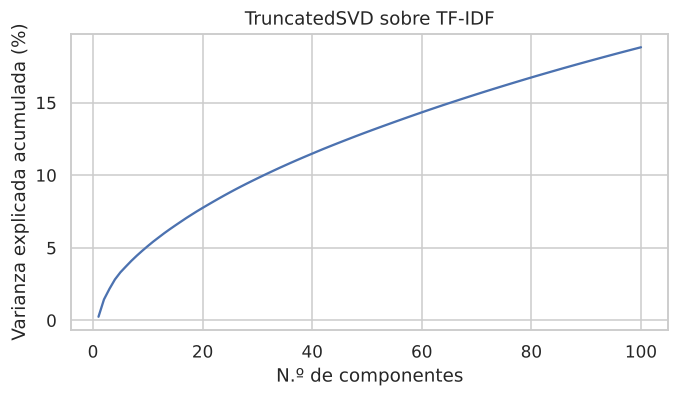

Varianza explicada con 100 componentes: 18.8 %


In [2]:
extra_stop = ["horse", "horses", "equine", "study", "results", "using", "used", "use", "based", "conclusion",
              "methods", "method", "data", "analysis", "significant", "significantly", "author", "authors",
              "rights", "reserved", "elsevier", "copyright", "journal", "published", "ltd", "background", "objective",
              "objectives", "clinical relevance", "conclusions", "results showed"]
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS.union(extra_stop)), ngram_range=(1, 2),
                        min_df=5, max_df=0.5, sublinear_tf=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b")
X_tfidf = tfidf.fit_transform(df["texto"].fillna(""))
print("Matriz TF-IDF:", X_tfidf.shape)

svd = TruncatedSVD(n_components=100, random_state=SEED)
X = Normalizer().fit_transform(svd.fit_transform(X_tfidf))
var = svd.explained_variance_ratio_.cumsum()
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 101), var * 100)
plt.xlabel("N.º de componentes"); plt.ylabel("Varianza explicada acumulada (%)")
plt.title("TruncatedSVD sobre TF-IDF")
plt.savefig(FIG / "art_svd_varianza.png"); plt.show()
print(f"Varianza explicada con 100 componentes: {var[-1]*100:.1f} %")

En texto la varianza queda muy repartida (miles de términos), así que no se busca un % alto: el objetivo de la SVD
es quitar ruido y sinónimos, no reconstruir la matriz completa.

## 2. K-Means: selección de k con codo, silhouette, Calinski-Harabasz y Davies-Bouldin

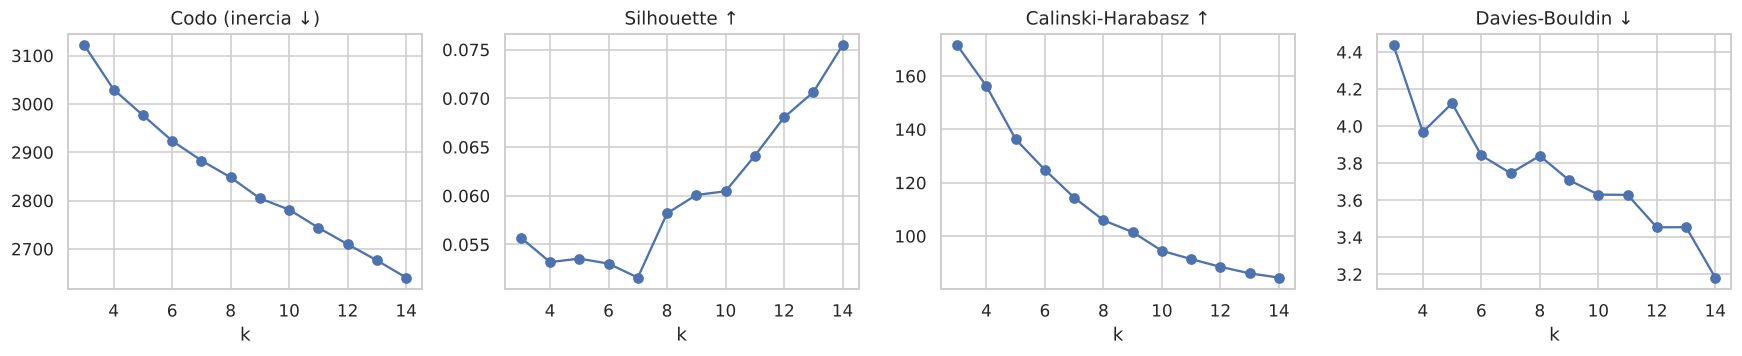

,k,inercia,silhouette,calinski,davies_bouldin
0,3,3121.324,0.056,171.515,4.437
1,4,3029.802,0.053,156.220,3.969
2,5,2976.653,0.054,136.269,4.123
3,6,2923.559,0.053,124.830,3.842
4,7,2882.930,0.052,114.426,3.746
5,8,2847.995,0.058,105.942,3.840
6,9,2804.588,0.060,101.488,3.709
7,10,2781.294,0.060,94.492,3.631
8,11,2743.853,0.064,91.382,3.629
9,12,2709.659,0.068,88.473,3.454


In [3]:
ks = range(3, 15)
res = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    res.append({"k": k, "inercia": km.inertia_, "silhouette": silhouette_score(X, km.labels_, random_state=SEED),
                "calinski": calinski_harabasz_score(X, km.labels_), "davies_bouldin": davies_bouldin_score(X, km.labels_)})
res = pd.DataFrame(res)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col, t in zip(axes, ["inercia", "silhouette", "calinski", "davies_bouldin"],
                      ["Codo (inercia ↓)", "Silhouette ↑", "Calinski-Harabasz ↑", "Davies-Bouldin ↓"]):
    ax.plot(res["k"], res[col], "o-"); ax.set_title(t); ax.set_xlabel("k")
plt.tight_layout(); plt.savefig(FIG / "art_kmeans_seleccion_k.png"); plt.show()
res.to_csv(OUT / "kmeans_seleccion_k.csv", index=False)
res.round(3)

**Criterio de elección:** en texto los valores de silhouette siempre son bajos (los temas se solapan). Se elige el k
que equilibra las métricas internas con la **interpretabilidad** de los clusters (que cada grupo tenga un tema
claro y que no haya grupos de muy pocos artículos). Se elige k = 8 (ver justificación en la celda siguiente).

In [4]:
K = 8
print(res.set_index("k").loc[K].round(3))
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)
df["cluster"] = km.labels_

# Términos más representativos de cada cluster: centroide proyectado de vuelta al espacio TF-IDF
centroides_tfidf = svd.inverse_transform(km.cluster_centers_)
terms = np.array(tfidf.get_feature_names_out())
top_terms = {c: ", ".join(terms[np.argsort(centroides_tfidf[c])[::-1][:10]]) for c in range(K)}
resumen = df.groupby("cluster").agg(n=("titulo", "size"), anio_mediana=("anio", "median"),
                                    citas_anio_med=("citas_por_anio", "median"),
                                    pct_outliers=("outlier", "mean"), pct_oa=("acceso_abierto", "mean"))
resumen["terminos_clave"] = pd.Series(top_terms)
pd.set_option("display.max_colwidth", 140)
resumen

inercia           2847.995
silhouette           0.058
calinski           105.942
davies_bouldin       3.840
Name: 8, dtype: float64


,n,anio_mediana,citas_anio_med,pct_outliers,pct_oa,terminos_clave
cluster,,,,,,
0,364,2019.5,1.166667,0.013736,0.708791,"inertial, lameness, movement, measurement, inertial measurement, gait, asymmetry, sensors, measurement unit, unit"
1,355,2024.0,0.714286,0.076056,0.735211,"vision, computer, computer vision, animal, behavior, monitoring, detection, tracking, animal behavior, learning"
2,476,2014.0,0.466667,0.002101,0.388655,"lameness, diagnosis, bone, imaging, diagnostic, lameness diagnosis, joint, clinical, examination, distal"
3,609,2020.0,0.333333,0.011494,0.602627,"gait, genetic, accelerometer, activity, different, model, classification, selection, breeding, research"
4,262,2022.0,2.000000,0.061069,0.721374,"dairy, cows, cattle, detection, lameness, dairy cattle, lameness detection, dairy cows, detection dairy, cow"
5,755,2013.0,0.531250,0.001325,0.474172,"gait, kinematics, kinematic, locomotion, stride, motion, trotting, trot, joint, force"
6,391,2024.0,1.000000,0.074169,0.675192,"pose, pose estimation, estimation, animal, animal pose, keypoint, tracking, behavior, learning, model"
7,611,2016.0,0.533333,0.001637,0.454992,"lameness, pain, treatment, joint, laminitis, clinical, osteoarthritis, lameness lameness, lame, chronic"


### Etiquetado de los perfiles
Los nombres se asignan leyendo los términos clave y los títulos más centrales de cada cluster (celda siguiente).
Se hace de forma programática por palabras clave dominantes para que sea reproducible.

In [5]:
for c in range(K):
    d = np.linalg.norm(X[df.cluster == c] - km.cluster_centers_[c], axis=1)
    idx = df.index[df.cluster == c][np.argsort(d)[:4]]
    print(f"\n=== Cluster {c} ({(df.cluster==c).sum()} artículos) ===\n  {top_terms[c]}")
    for t in df.loc[idx, "titulo"]:
        print("   -", t[:110])


=== Cluster 0 (364 artículos) ===
  inertial, lameness, movement, measurement, inertial measurement, gait, asymmetry, sensors, measurement unit, unit
   - Repeatability of gait analysis measurements in Thoroughbreds in training
   - Validation of a single body inertial measurement unit sensor for symmetry measurement in horses
   - Investigation of Thresholds for Asymmetry Indices to Represent the Visual Assessment of Single Limb Lameness b
   - Comparison of a standalone consumer grade smartphone with a specialist inertial measurement unit for quantific

=== Cluster 1 (355 artículos) ===
  vision, computer, computer vision, animal, behavior, monitoring, detection, tracking, animal behavior, learning
   - Developing CAMIC-Behav:A Computer Vision Framework for Behavioral Monitoring of Dromedary Camels
   - An Introduction to Automated Visual Sensemaking for Animal Production Systems
   - Application of Computer Vision for Livestock Farming: A Bibliometric Analysis
   - Analysis of the 

In [6]:
REGLAS_NOMBRE = [  # (patrón buscado en los 5 términos más fuertes, etiqueta) – se evalúan en orden
    ("pose", "Estimación de pose animal (deep learning)"),
    ("computer vision|vision", "Visión por computador para monitoreo animal"),
    ("inertial|sensor|accelerom", "Sensores inerciales y asimetría de marcha"),
    ("dairy|cows|cattle", "Detección de cojera en bovinos"),
    ("radiograph|osteo|treatment|bone|joint", "Patologías articulares y tratamiento"),
    ("diagnosis|pain|forelimb|lame", "Diagnóstico clínico de la cojera"),
    ("kinemat|stride|locomotion", "Cinemática y biomecánica de la marcha"),
    ("genetic|breeding|welfare|performance", "Genética, bienestar y rendimiento"),
]
etiquetas = {}
for c in range(K):
    t5 = ", ".join(top_terms[c].split(", ")[:5])
    nombre = next((n for p, n in REGLAS_NOMBRE if pd.Series([t5]).str.contains(p).iloc[0] and n not in etiquetas.values()), None)
    etiquetas[c] = nombre or f"Tema mixto {c}"
df["perfil"] = df["cluster"].map(etiquetas)
resumen.insert(0, "perfil", pd.Series(etiquetas))
resumen[["perfil", "n", "anio_mediana", "citas_anio_med", "pct_outliers", "pct_oa"]].round(2)

,perfil,n,anio_mediana,citas_anio_med,pct_outliers,pct_oa
cluster,,,,,,
0,Sensores inerciales y asimetría de marcha,364,2019.5,1.17,0.01,0.71
1,Visión por computador para monitoreo animal,355,2024.0,0.71,0.08,0.74
2,Patologías articulares y tratamiento,476,2014.0,0.47,0.00,0.39
3,"Genética, bienestar y rendimiento",609,2020.0,0.33,0.01,0.60
4,Detección de cojera en bovinos,262,2022.0,2.00,0.06,0.72
5,Cinemática y biomecánica de la marcha,755,2013.0,0.53,0.00,0.47
6,Estimación de pose animal (deep learning),391,2024.0,1.00,0.07,0.68
7,Diagnóstico clínico de la cojera,611,2016.0,0.53,0.00,0.45


## 3. Visualización 2D (t-SNE sobre el espacio SVD)

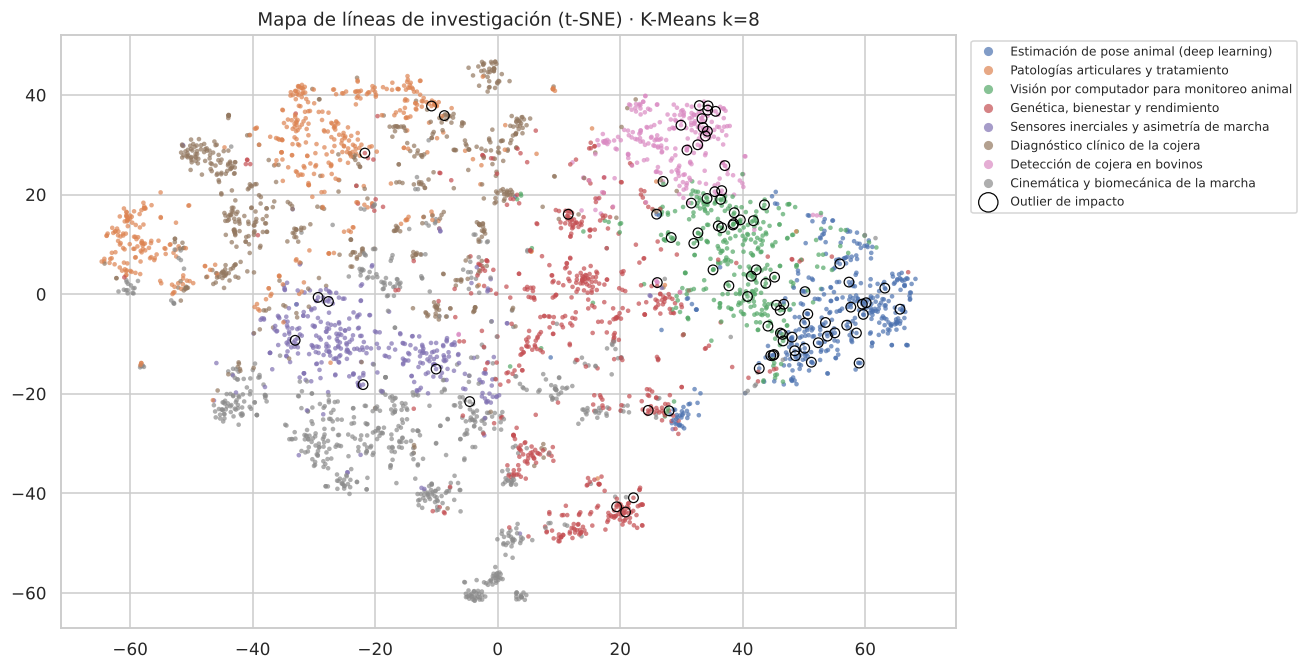

In [7]:
emb = TSNE(n_components=2, perplexity=40, random_state=SEED, init="pca").fit_transform(X)
df["tsne_x"], df["tsne_y"] = emb[:, 0], emb[:, 1]
plt.figure(figsize=(10.5, 7))
sns.scatterplot(data=df, x="tsne_x", y="tsne_y", hue="perfil", s=9, alpha=.7, linewidth=0)
plt.scatter(df.loc[df.outlier, "tsne_x"], df.loc[df.outlier, "tsne_y"], s=40, facecolors="none", edgecolors="black",
            linewidths=.8, label="Outlier de impacto")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, markerscale=2)
plt.title("Mapa de líneas de investigación (t-SNE) · K-Means k=8"); plt.xlabel(""); plt.ylabel("")
plt.savefig(FIG / "art_tsne_clusters.png"); plt.show()

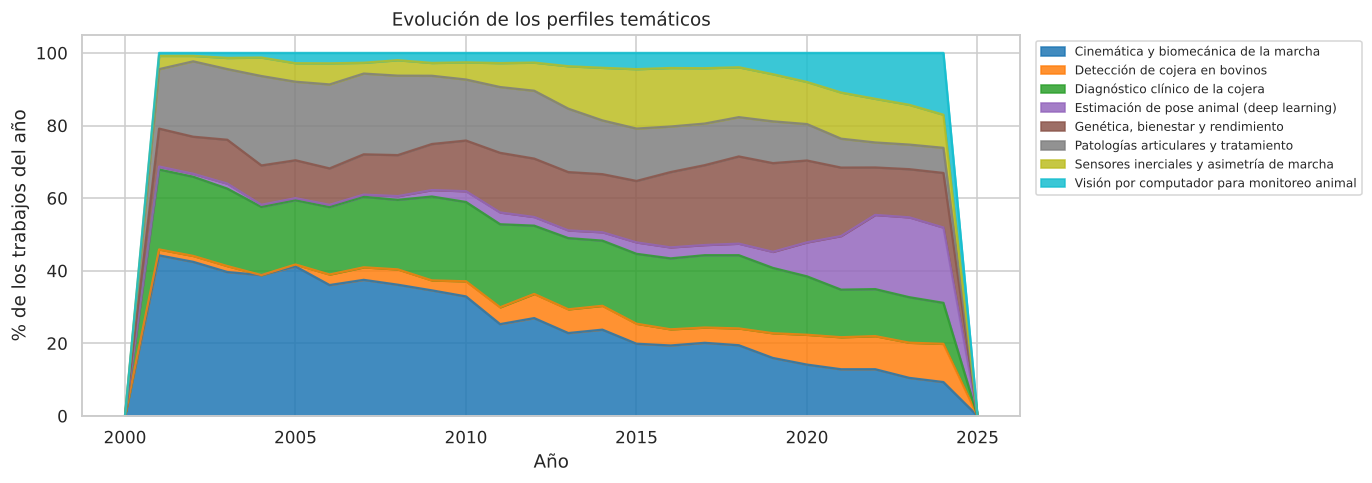

In [8]:
evol = pd.crosstab(df["anio"], df["perfil"]).loc[2000:2025]
evol_pct = evol.div(evol.sum(axis=1), axis=0).rolling(3, center=True).mean() * 100
evol_pct.plot.area(figsize=(11, 4.5), alpha=.85, cmap="tab10")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.ylabel("% de los trabajos del año"); plt.xlabel("Año"); plt.title("Evolución de los perfiles temáticos")
plt.savefig(FIG / "art_evolucion_perfiles.png"); plt.show()

## 4. Comparación con clustering jerárquico y DBSCAN

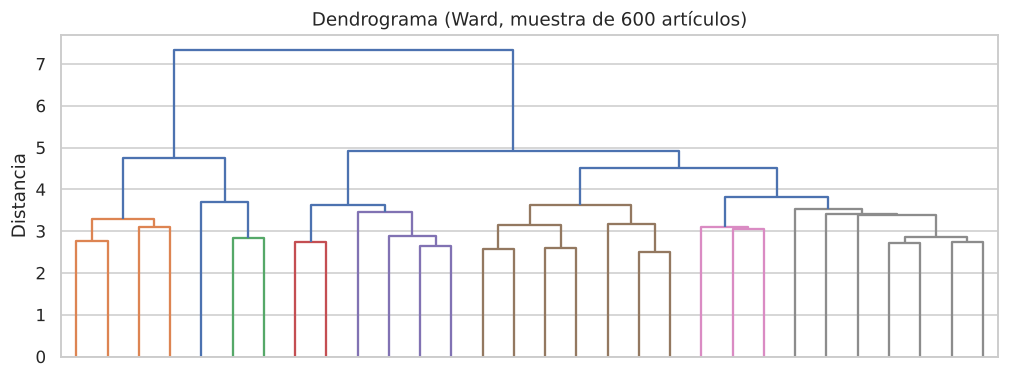

DBSCAN eps=0.749: 33 clusters, ruido=46.8 %


,algoritmo,silhouette,ARI_vs_KMeans,pct_ruido
0,K-Means (k=8),0.056,1.000,0.000
1,Jerárquico Ward (k=8),0.041,0.345,0.000
2,DBSCAN,0.131,0.118,46.822


In [9]:
# Jerárquico (Ward) sobre una muestra para el dendrograma + asignación completa con AgglomerativeClustering
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
rng = np.random.default_rng(SEED); muestra = rng.choice(len(X), 600, replace=False)
Z = linkage(X[muestra], method="ward")
plt.figure(figsize=(11, 3.8))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=Z[-(K - 1), 2], no_labels=True)
plt.title("Dendrograma (Ward, muestra de 600 artículos)"); plt.ylabel("Distancia")
plt.savefig(FIG / "art_dendrograma.png"); plt.show()

# DBSCAN: eps a partir de la curva de k-distancias (k = min_samples)
min_s = 10
dist, _ = NearestNeighbors(n_neighbors=min_s).fit(X).kneighbors(X)
kd = np.sort(dist[:, -1])
eps = float(np.quantile(kd, 0.30))
db = DBSCAN(eps=eps, min_samples=min_s).fit(X)
print(f"DBSCAN eps={eps:.3f}: {len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)} clusters, ruido={np.mean(db.labels_==-1)*100:.1f} %")

from sklearn.metrics import adjusted_rand_score
comp = pd.DataFrame({
    "algoritmo": ["K-Means (k=8)", "Jerárquico Ward (k=8)", "DBSCAN"],
    "silhouette": [silhouette_score(X, km.labels_), silhouette_score(X, agg.labels_),
                   silhouette_score(X[db.labels_ != -1], db.labels_[db.labels_ != -1]) if len(set(db.labels_)) > 2 else np.nan],
    "ARI_vs_KMeans": [1.0, adjusted_rand_score(km.labels_, agg.labels_), adjusted_rand_score(km.labels_, db.labels_)],
    "pct_ruido": [0, 0, np.mean(db.labels_ == -1) * 100],
})
comp.round(3)

**Lectura:** K-Means y Ward coinciden solo parcialmente (ARI bajo-moderado): los temas se solapan y las fronteras
entre perfiles son difusas, algo esperable en literatura científica. DBSCAN muestra un silhouette mayor, pero es
engañoso: se calcula sin el ~50 % de artículos que marca como ruido y fragmenta el corpus en decenas de micro-grupos.
En alta dimensión las densidades son casi homogéneas, que es el peor caso para DBSCAN. Se conserva **K-Means** porque
asigna todos los artículos, tiene el mejor Calinski-Harabasz y da perfiles interpretables.

## 5. Reglas de asociación (Apriori vs FP-Growth)
Cada artículo es una **transacción** y sus *keywords* de OpenAlex son los **ítems**. Se conservan las 150 keywords
más frecuentes (se quitan "horse/horses/equine", que aparecen casi siempre y no aportan información).

In [10]:
trans = df["keywords"].fillna("").str.lower().str.split(";").apply(
    lambda ks: sorted({k.strip() for k in ks if k.strip() and k.strip() not in {"horse", "horses", "equine", "equines"}}))
freq = pd.Series([k for t in trans for k in t]).value_counts()
top_items = set(freq.head(150).index)
trans_f = [[k for k in t if k in top_items] for t in trans]
trans_f = [t for t in trans_f if len(t) >= 2]
te = TransactionEncoder(); B = pd.DataFrame(te.fit(trans_f).transform(trans_f), columns=te.columns_)
print("Transacciones:", B.shape)

t0 = time.time(); fi_ap = apriori(B, min_support=0.008, use_colnames=True, max_len=3); t_ap = time.time() - t0
t0 = time.time(); fi_fp = fpgrowth(B, min_support=0.008, use_colnames=True, max_len=3); t_fp = time.time() - t0
print(f"Apriori: {len(fi_ap)} conjuntos en {t_ap:.2f}s | FP-Growth: {len(fi_fp)} conjuntos en {t_fp:.2f}s")

reglas = association_rules(fi_fp, metric="lift", min_threshold=1.5)
reglas = reglas[(reglas["confidence"] >= 0.3)].sort_values(["lift", "confidence"], ascending=False)
reglas["antecedente"] = reglas["antecedents"].apply(lambda s: " + ".join(sorted(s)))
reglas["consecuente"] = reglas["consequents"].apply(lambda s: " + ".join(sorted(s)))
print("Reglas con lift ≥ 1.5 y confianza ≥ 0.3:", len(reglas))
reglas[["antecedente", "consecuente", "support", "confidence", "lift"]].head(20).round(3)

Transacciones: (2500, 150)
Apriori: 222 conjuntos en 0.04s | FP-Growth: 222 conjuntos en 0.01s
Reglas con lift ≥ 1.5 y confianza ≥ 0.3: 52


,antecedente,consecuente,support,confidence,lift
84,canter + trotting,walks,0.009,0.564,23.504
85,walks,canter + trotting,0.009,0.367,23.504
101,human pose estimation,animal pose estimation,0.009,0.767,22.817
83,trotting + walks,canter,0.009,0.407,18.861
86,canter,trotting + walks,0.009,0.407,18.861
80,walks,canter,0.009,0.367,16.975
81,canter,walks,0.009,0.407,16.975
27,forelimb lameness,equine lameness + hindlimb lameness,0.015,0.314,16.023
26,equine lameness + hindlimb lameness,forelimb lameness,0.015,0.776,16.023
122,locomotion score,dairy cattle + lameness detection,0.011,0.587,14.529


In [11]:
# Reglas que tocan la intersección de interés: cojera ↔ visión / sensores / ML
interes = reglas[reglas.apply(lambda r: any(w in (r.antecedente + " " + r.consecuente)
                                            for w in ["lame", "gait", "pose", "deep", "machine", "sensor", "inertial", "kinemat"]), axis=1)]
interes[["antecedente", "consecuente", "support", "confidence", "lift"]].head(15).round(3)

,antecedente,consecuente,support,confidence,lift
101,human pose estimation,animal pose estimation,0.009,0.767,22.817
27,forelimb lameness,equine lameness + hindlimb lameness,0.015,0.314,16.023
26,equine lameness + hindlimb lameness,forelimb lameness,0.015,0.776,16.023
122,locomotion score,dairy cattle + lameness detection,0.011,0.587,14.529
118,lameness detection + locomotion score,dairy cattle,0.011,0.964,13.855
25,equine lameness + forelimb lameness,hindlimb lameness,0.015,0.691,12.890
50,dairy cattle + gait analysis,lameness detection,0.010,0.897,10.188
1,keypoint detection,animal pose estimation,0.010,0.338,10.055
18,forelimb lameness,hindlimb lameness,0.024,0.496,9.251
19,hindlimb lameness,forelimb lameness,0.024,0.448,9.251


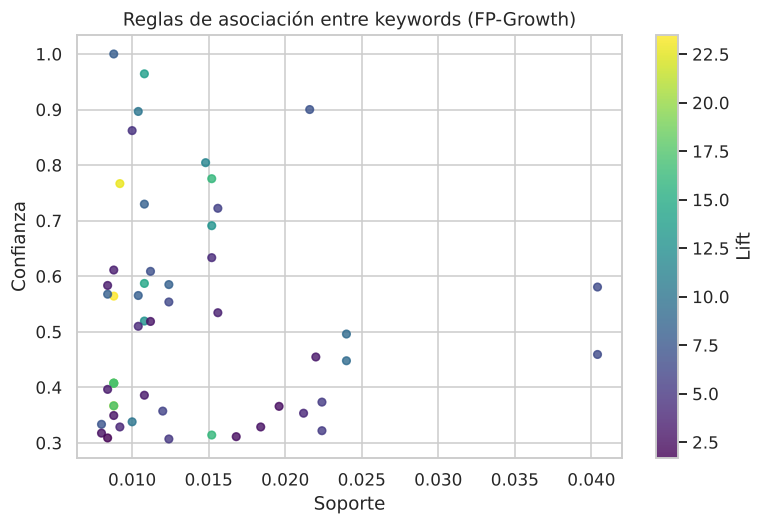

In [12]:
plt.figure(figsize=(8, 5))
sc = plt.scatter(reglas["support"], reglas["confidence"], c=reglas["lift"], cmap="viridis", s=25, alpha=.8)
plt.colorbar(sc, label="Lift"); plt.xlabel("Soporte"); plt.ylabel("Confianza")
plt.title("Reglas de asociación entre keywords (FP-Growth)")
plt.savefig(FIG / "art_reglas_scatter.png"); plt.show()

## 6. El vacío que justifica el proyecto
Se mide cuántos trabajos combinan **caballo + cojera + visión por computador** frente a cada componente por separado,
y cuántos tienen autores de Latinoamérica.

In [13]:
t = df["texto"].str.lower()
caballo = t.str.contains(r"horse|equine|pony")
cojera = t.str.contains(r"lame")
vision = df["tema_vision"]
latam = df["paises"].fillna("").str.contains(r"\b(?:CO|BR|AR|MX|CL|PE|EC|UY|VE|BO|PY|CR|CU)\b")
brecha = pd.Series({
    "Caballo": caballo.sum(),
    "Caballo + cojera": (caballo & cojera).sum(),
    "Caballo + cojera + visión": (caballo & cojera & vision).sum(),
    "  …con autores de Latinoamérica": (caballo & cojera & vision & latam).sum(),
    "  …con autores de Colombia": (caballo & cojera & vision & df["paises"].fillna("").str.contains(r"\bCO\b")).sum(),
})
brecha.to_frame("n_trabajos")

,n_trabajos
Caballo,2663
Caballo + cojera,1331
Caballo + cojera + visión,175
…con autores de Latinoamérica,5
…con autores de Colombia,1


In [14]:
df.drop(columns=["texto"]).to_csv(OUT / "articulos_con_clusters.csv", index=False)
reglas[["antecedente", "consecuente", "support", "confidence", "lift"]].to_csv(OUT / "reglas_asociacion.csv", index=False)
print("Exportado articulos_con_clusters.csv y reglas_asociacion.csv")

Exportado articulos_con_clusters.csv y reglas_asociacion.csv
